# TP6 - Agentic RAG avec Groq (gpt-oss) sur mon rapport du projet de fin d'annee 

In [2]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_groq import ChatGroq
from IPython.display import Markdown, Image, display

C:\Users\rabab\AppData\Local\Temp\ipykernel_16072\1692017134.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


In [1]:
import os, getpass
if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"] = getpass.getpass("GROQ_API_KEY: ")

In [3]:
import sys
!uv pip install --python "{sys.executable}" langchain-text-splitters langchain-groq langchain-huggingface langchain-chroma langchain-community sentence-transformers pypdf langgraph

Checked 8 packages in 54ms


from langchain_community.document_loaders import PyPDFDirectoryLoader
# Path of all Documents : Abount AI Initiative
ai_initiative_pdf_paths = [ f"./resources/{file}" for file in os.listdir("./resources")]

In [4]:
# Creating PDF loader object
loader = PyPDFDirectoryLoader(path="./resources/")

In [5]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

ai_initiative_chunks = loader.load_and_split(text_splitter=text_splitter)
print(f"{len(ai_initiative_chunks)} chunks créés")

159 chunks créés


## Retriever (embeddings si possible, sinon BM25 sans fichiers compilés)

In [26]:
embedding_model = HuggingFaceEmbeddings(
    model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)

retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)

23:58:30 [INFO] No device provided, using cpu
23:58:30 [INFO] HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 "HTTP/1.1 200 OK"
23:58:30 [INFO] Loading SentenceTransformer model from sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1874.05it/s]
23:58:31 [INFO] HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
23:58:31 [INFO] HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
23:58:33 [INFO] HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 "HTTP/1.1 200 OK"


## Test manuel du retriever

In [27]:
test_query = "C'est quoi le SVM?"
print(f"🔍 Test Query: {test_query}")
print("=" * 80)

relevant_docs = retriever.invoke(test_query)
print(f"\nRetrieved {len(relevant_docs)} relevant chunks:\n")

for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f"   Source: {doc.metadata.get('source', 'Unknown')}")
    print(f"   Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"   Content: {doc.page_content[:100]}...")
    print("-" * 80 + "\n")

🔍 Test Query: C'est quoi le SVM?

Retrieved 10 relevant chunks:

📄 Result 1:
   Source: resources\RAPPORT_AI_PROJECT.pdf
   Page: 19
   Content: Grâce à sa robustesse théorique, sa capacité de généralisation et ses bonnes performances
sur des do...
--------------------------------------------------------------------------------

📄 Result 2:
   Source: resources\RAPPORT_AI_PROJECT.pdf
   Page: 19
   Content: Grâce à sa robustesse théorique, sa capacité de généralisation et ses bonnes performances
sur des do...
--------------------------------------------------------------------------------

📄 Result 3:
   Source: resources\RAPPORT_AI_PROJECT.pdf
   Page: 19
   Content: ˆ𝑦∈
{0, . . . ,9}
Figure 1– Architecture fonctionnelle du classifieur SVM linéaire appliqué à la bas...
--------------------------------------------------------------------------------



## Outil retriever

In [28]:
from langchain_core.tools import tool

@tool
def retriever_tool(query: str) -> str:
    """Recherche dans le rapport du projet IA « Handwritten Digit Recognition »
    (reconnaissance de chiffres manuscrits sur MNIST avec SVM, MLP et CNN).
    Utilisez cet outil pour obtenir des informations sur :
    - Le prétraitement des données et l'augmentation de données
    - Les modèles SVM (avec ACP), MLP et CNN et leurs architectures
    - Les techniques de régularisation (L2, Batch Normalization, Dropout, Label Smoothing,
      Early Stopping, ReduceLROnPlateau)
    - Les résultats expérimentaux, métriques et comparaisons entre modèles

    Args:
        query: Question en langage naturel sur le contenu du rapport

    Returns:
        str: Extraits pertinents du rapport avec leur numéro de page
    """
    try:
        docs = retriever.invoke(query)
        return "\n\n".join(
            f"[page {d.metadata.get('page', '?')}] {d.page_content}" for d in docs
        )
    except Exception as e:
        return f"Error querying the report: {str(e)}"

## Modèle Groq

In [29]:
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

## State and System message

In [30]:
import logging
from typing import Annotated, Sequence, Literal, TypedDict
from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S"
)
logger = logging.getLogger(__name__)

In [31]:
class SimpleAgentState(TypedDict):
    """State of the agent: conversation history with message accumulation."""
    messages: Annotated[Sequence, add_messages]

In [32]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'analyse du rapport de projet
« Handwritten Digit Recognition using Machine and Deep Learning Algorithms »
(comparaison de SVM, MLP et CNN sur la base MNIST).
Pour toute question sur le contenu du rapport, utilisez l'outil de recherche
puis répondez uniquement à partir des extraits récupérés.
N'ajoutez pas d'informations externes et ne mentionnez pas le mot « contexte »
dans votre réponse.
Indiquez toujours la ou les pages du rapport d'où provient l'information.
Si la réponse ne peut pas être trouvée dans les extraits, répondez par :
"Je ne sais pas - cette information n'est pas disponible dans le rapport."
Répondez dans la langue de la question.
"""

## Agent Node

In [33]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the LLM with system prompt and current state."""
    logger.info("AGENT NODE: Processing request...")
    messages = [SystemMessage(content=agentic_rag_system_message)] + list(state["messages"])

    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)

    if getattr(response, "tool_calls", None):
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"  {i}. {tool_call['name']}")
    else:
        logger.info("✓ Agent generated final response (no tools needed)")

    return {"messages": [response]}

## Condition de routage

In [34]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Determines whether to continue to tools or end."""
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        logger.info("🔀 ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"

## creat, compile and display the Graph

23:59:32 [INFO] ✅ Agent créé avec succès



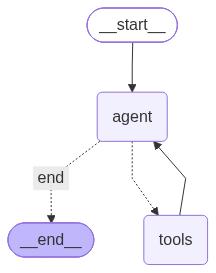

In [35]:
workflow = StateGraph(SimpleAgentState)

original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info("Tools executed successfully")
    return result

workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)
workflow.set_entry_point("agent")

workflow.add_conditional_edges(
    "agent",
    should_continue,
    {"tools": "tools", "end": END}
)
workflow.add_edge("tools", "agent")

graph = workflow.compile()
logger.info("✅ Agent créé avec succès\n")
display(Image(graph.get_graph().draw_mermaid_png()))





## Tester l'application Agentic RAG

In [36]:
import time

queries = [
    "Quel modèle obtient les meilleures performances et avec quelle précision ?",
    "Quelles techniques de régularisation ont été utilisées pour le MLP et le CNN ?",
    "Pourquoi l'ACP est-elle utilisée avec le SVM ?",
    "Quel est le prix de l'action NVIDIA ?",
]

for query in queries:
    print("=" * 100)
    print(f"Query: {query}")
    print("=" * 100)
    for attempt in range(3):
        try:
            result = graph.invoke({"messages": [HumanMessage(content=query)]})
            print("*" * 100)
            print("                                    la reponse est :" )
            print("*" * 100)
            display(Markdown(result["messages"][-1].content))
            break
        except Exception as e:
            print(f"Limite atteinte, nouvelle tentative dans 30 s... ({type(e).__name__})")
            time.sleep(30)
    time.sleep(20)

23:59:37 [INFO] AGENT NODE: Processing request...
23:59:37 [INFO] Calling LLM with tools...


Query: Quel modèle obtient les meilleures performances et avec quelle précision ?


23:59:37 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
23:59:37 [INFO] ✓ Agent decided to use 1 tool(s)
23:59:37 [INFO]   1. retriever_tool
23:59:37 [INFO] 🔀 ROUTING: Continuing to TOOLS node
23:59:37 [INFO] TOOL NODE: Executing tools...
23:59:37 [INFO] Tools executed successfully
23:59:37 [INFO] AGENT NODE: Processing request...
23:59:37 [INFO] Calling LLM with tools...
23:59:38 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
23:59:38 [INFO] ✓ Agent generated final response (no tools needed)
23:59:38 [INFO] ROUTING: Ending workflow (final response ready)


****************************************************************************************************
                                    la reponse est :
****************************************************************************************************


Le modèle **CNN** obtient les meilleures performances, avec une précision (accuracy) sur le jeu de test de **99,64 %**. [page 69]

23:59:58 [INFO] AGENT NODE: Processing request...
23:59:58 [INFO] Calling LLM with tools...


... (13 outputs left out)

Query: Quel est le prix de l'action NVIDIA ?


00:05:51 [INFO] HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
00:05:51 [INFO] ✓ Agent generated final response (no tools needed)
00:05:51 [INFO] ROUTING: Ending workflow (final response ready)


****************************************************************************************************
                                    la reponse est :
****************************************************************************************************


Je ne sais pas - cette information n'est pas disponible dans le rapport.